In [48]:
import osmnx as ox
import pandas as pd 
import geopandas as gpd
import sklearn
import matplotlib

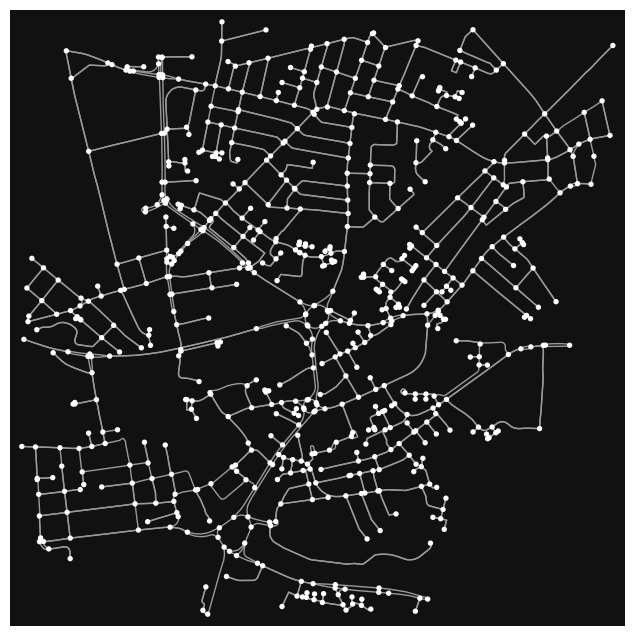

In [49]:
# define a point at cockedge roundabout
location_point = (53.392556, -2.586361)

# create network from point, inside bounding box of N, S, E, W each 1000m from point
ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.http_user_agent = "ev-demand-research (bradleygaryparker@gmail.com)"
G = ox.graph.graph_from_point(location_point, dist=1000, dist_type="bbox", network_type="drive")
ox.save_graphml(G, filepath='data/cockedge_roundabout.graphml')
fig, ax = ox.plot.plot_graph(G)

In [50]:
import multiprocessing as mp
import numpy as np

In [51]:
np.random.seed(37)
ox.settings.log_console = True
ox.__version__

'2.1.1'

In [52]:
Gp = ox.projection.project_graph(G)

In [53]:
# randomly sample n points spatially-constrained to the network's geometry
points = ox.utils_geo.sample_points(ox.convert.to_undirected(Gp), n=100)
X = points.x.values
Y = points.y.values
X0 = X.mean()
Y0 = Y.mean()

In [54]:
# find each nearest node to several points, and optionally return distance
nodes, dists = ox.distance.nearest_nodes(Gp, X, Y, return_dist=True)

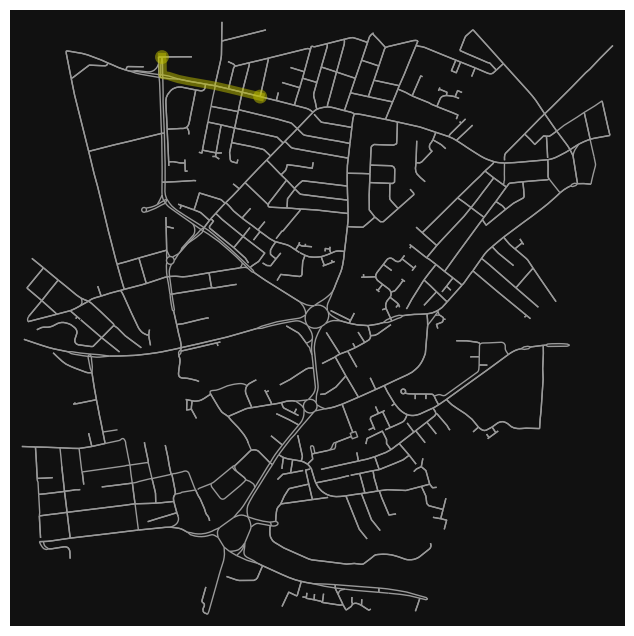

In [55]:
# find the shortest path (by distance) between these nodes then plot it
orig = next(iter(G))
dest = list(G)[120]
route = ox.routing.shortest_path(G, orig, dest, weight="length")
fig, ax = ox.plot.plot_graph_route(G, route, route_color="y", route_linewidth=6, node_size=0)

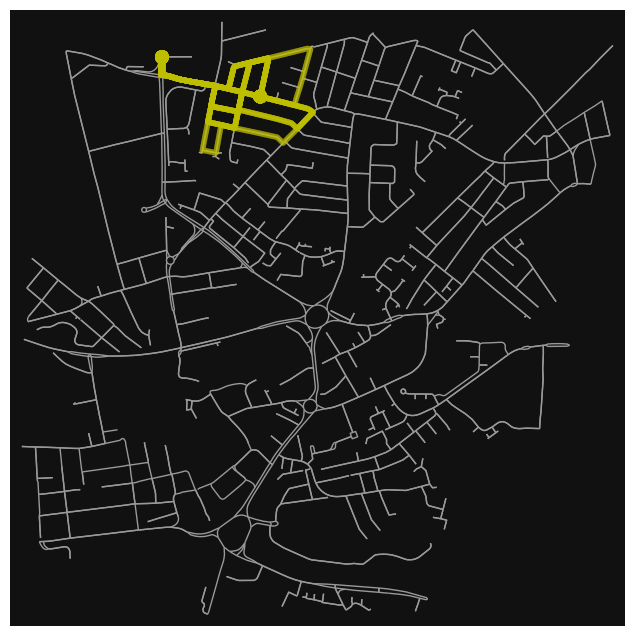

In [56]:
routes = ox.routing.k_shortest_paths(G, orig, dest, k=30, weight="length")
fig, ax = ox.plot.plot_graph_routes(
    G,
    list(routes),
    route_colors="y",
    route_linewidth=4,
    node_size=0,
)

In [57]:
# impute speed on all edges missing data
G = ox.routing.add_edge_speeds(G)

# calculate travel time (seconds) for all edges
G = ox.routing.add_edge_travel_times(G)

In [58]:
# see mean speed/time values by road type
edges = ox.convert.graph_to_gdfs(G, nodes=False)
edges["highway"] = edges["highway"].astype(str)
edges.groupby("highway")[["length", "speed_kph", "travel_time"]].mean().round(1)

,length,speed_kph,travel_time
highway,,,
"['living_street', 'unclassified']",57.1,32.2,6.4
"['residential', 'unclassified']",120.4,40.2,10.8
primary,60.1,48.3,4.5
residential,61.5,33.1,6.7
tertiary,56.1,47.4,4.3
tertiary_link,46.1,48.3,3.4
trunk,83.5,48.3,6.2
trunk_link,62.0,48.3,4.6
unclassified,72.9,40.9,7.0


In [59]:
# same thing again, but this time pass in a few default speed values (km/hour)
# to fill in edges with missing `maxspeed` from OSM
hwy_speeds = {"residential": 35, "secondary": 50, "tertiary": 60}
G = ox.routing.add_edge_speeds(G, hwy_speeds=hwy_speeds)
G = ox.routing.add_edge_travel_times(G)

In [60]:
# calculate two routes by minimizing travel distance vs travel time
orig = list(G)[1]
dest = list(G)[60]
route1 = ox.routing.shortest_path(G, orig, dest, weight="length")
route2 = ox.routing.shortest_path(G, orig, dest, weight="travel_time")

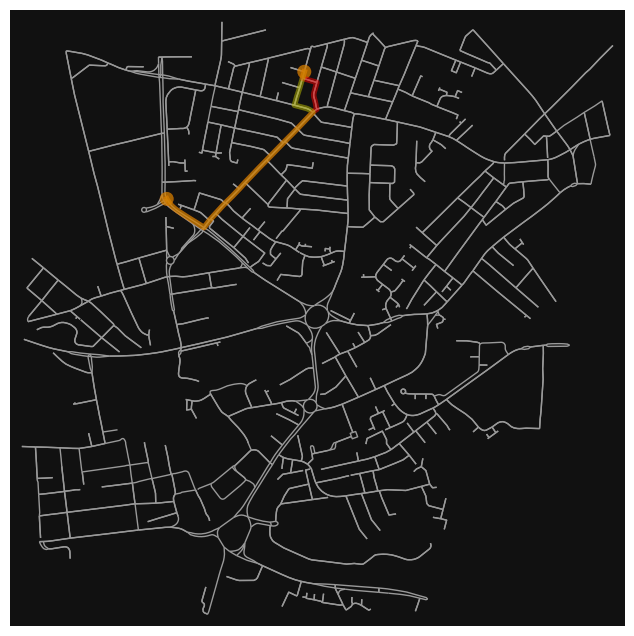

In [61]:
# plot the routes
fig, ax = ox.plot.plot_graph_routes(
    G,
    routes=[route1, route2],
    route_colors=["r", "y"],
    route_linewidth=6,
    node_size=0,
)

In [62]:
# compare the two routes
route1_length = int(sum(ox.routing.route_to_gdf(G, route1, weight="length")["length"]))
route2_length = int(sum(ox.routing.route_to_gdf(G, route2, weight="travel_time")["length"]))
route1_time = int(sum(ox.routing.route_to_gdf(G, route1, weight="length")["travel_time"]))
route2_time = int(sum(ox.routing.route_to_gdf(G, route2, weight="travel_time")["travel_time"]))
print("Route 1 is", route1_length, "meters and takes", route1_time, "seconds.")
print("Route 2 is", route2_length, "meters and takes", route2_time, "seconds.")

Route 1 is 878 meters and takes 71 seconds.
Route 2 is 881 meters and takes 70 seconds.


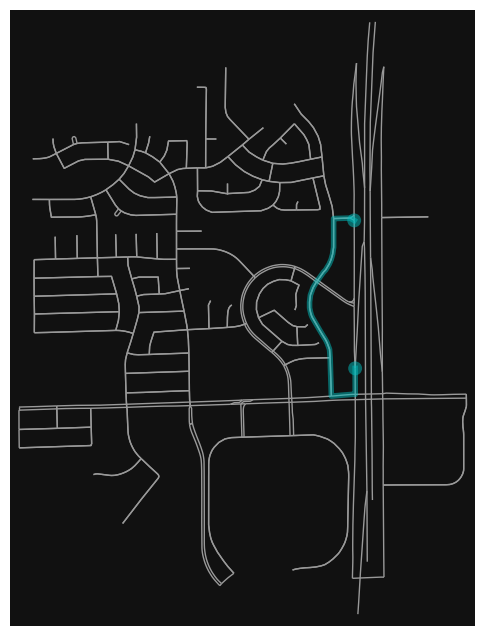

In [63]:
G2 = ox.graph.graph_from_address(
    "N. Sicily Pl., Chandler, Arizona",
    dist=800,
    network_type="drive",
    truncate_by_edge=True,
)
origin = (33.307792, -111.894940)
destination = (33.312994, -111.894998)
origin_node = ox.distance.nearest_nodes(G2, origin[1], origin[0])
destination_node = ox.distance.nearest_nodes(G2, destination[1], destination[0])
route = ox.routing.shortest_path(G2, origin_node, destination_node)
fig, ax = ox.plot.plot_graph_route(G2, route, route_color="c", node_size=0)

In [64]:
# network of the canals of amsterdam
place = "Amsterdam, Netherlands"
G = ox.graph.graph_from_place(place, custom_filter='["waterway"~"canal"]')

ResponseStatusCodeError: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md
